In [4]:
import pandas as pd

df = pd.read_csv("../../data/processed/worldcover_features.csv")

df.head()

,tree_cover,grassland,built_up,bare_sparse_vegetation,permanent_water,moss_lichen,route,snow_ice,cropland,shrubland
0,0.418710,0.510116,0.042464,0.007023,0.003020,0.018667,t312489045_dolomyths run 42k - 12,NaN,NaN,NaN
1,0.268495,0.333235,0.041239,0.269381,0.000148,0.032592,t312644169_dmr 22k skyrun - 13. juli,0.054911,NaN,NaN
2,0.233338,0.691770,0.038133,0.028191,0.001420,0.005681,E101_2026_5258b44cf2,0.001451,0.000015,NaN
3,0.390810,0.510928,0.097546,0.000717,NaN,NaN,E16_2024_2a605ace7d,NaN,NaN,NaN
4,0.322675,0.585706,0.049252,0.030667,0.002746,0.007899,E35_2026_4be7247326,0.001056,NaN,NaN


In [5]:
df.describe()

,tree_cover,grassland,built_up,bare_sparse_vegetation,permanent_water,moss_lichen,snow_ice,cropland,shrubland
count,97.000000,97.000000,97.000000,95.000000,83.000000,52.000000,38.000000,68.000000,24.000000
mean,0.472304,0.362732,0.070919,0.029172,0.007935,0.057029,0.041183,0.011077,0.017035
std,0.196793,0.178078,0.050864,0.050057,0.009671,0.068886,0.068571,0.012951,0.022983
min,0.030071,0.055036,0.006340,0.000033,0.000063,0.000042,0.000012,0.000015,0.000012
25%,0.322082,0.232237,0.038279,0.001581,0.002110,0.007645,0.002341,0.003142,0.000119
50%,0.489834,0.326544,0.060519,0.007023,0.004226,0.029327,0.011048,0.007288,0.000822
75%,0.634912,0.510928,0.093613,0.040165,0.010968,0.079740,0.051497,0.014083,0.035270
max,0.820327,0.754332,0.332915,0.271688,0.064822,0.339819,0.316431,0.067164,0.060623


In [6]:
df.isna().sum()

tree_cover                 0
grassland                  0
built_up                   0
bare_sparse_vegetation     2
permanent_water           14
moss_lichen               45
route                      0
snow_ice                  59
cropland                  29
shrubland                 73
dtype: int64

## Histogram with class frequency

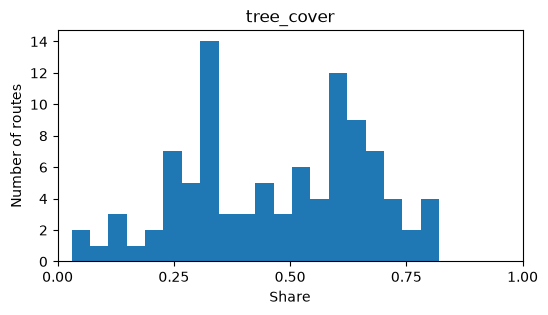

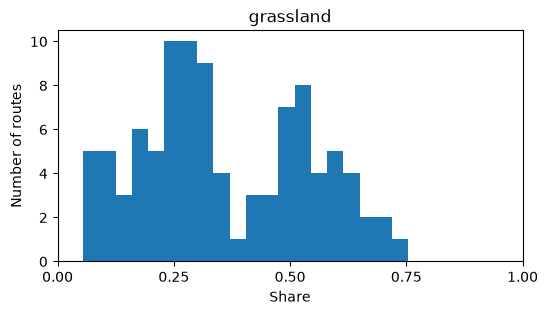

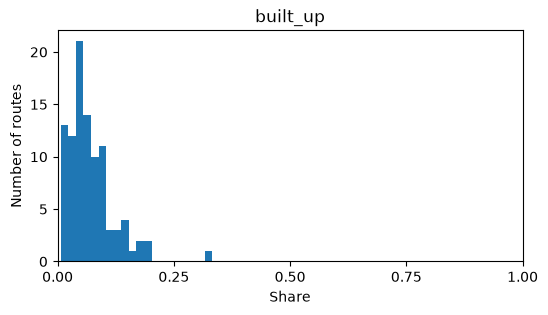

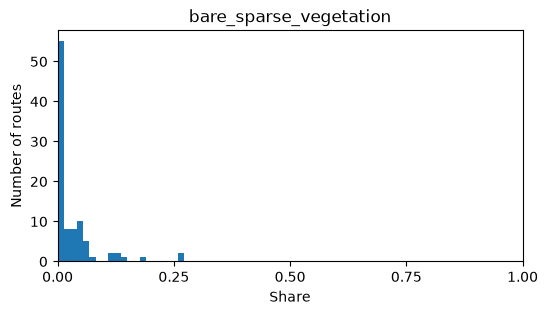

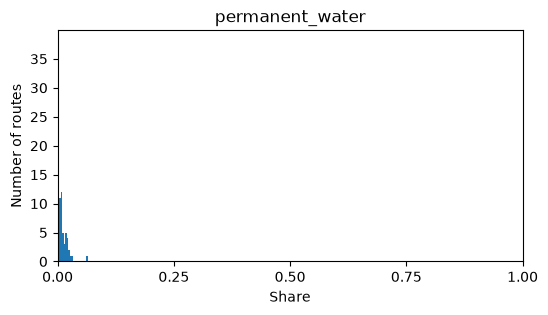

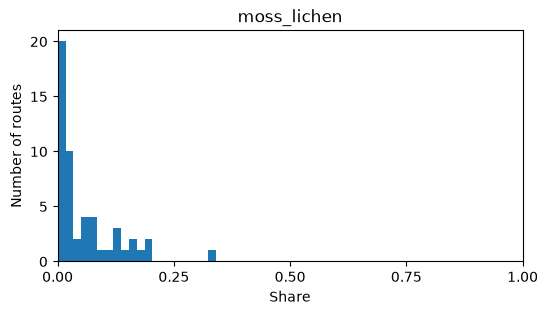

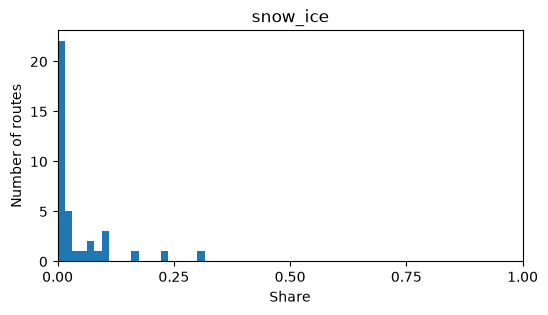

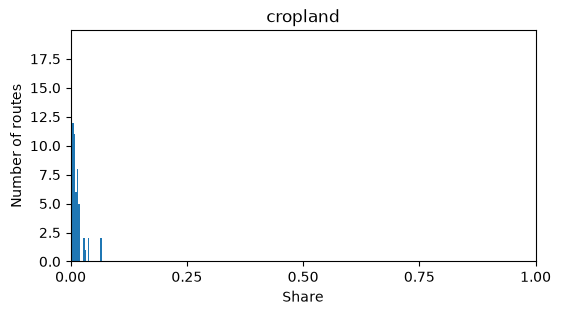

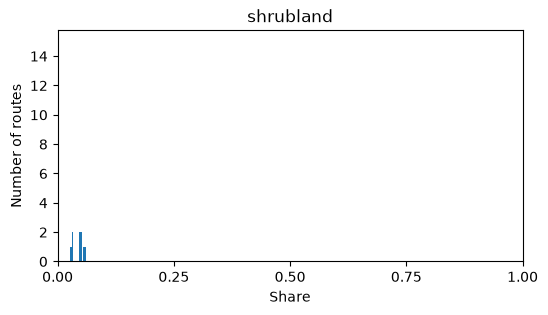

In [10]:
import matplotlib.pyplot as plt

feature_columns = df.columns.drop("route")

for col in feature_columns:
    plt.figure(figsize=(6, 3))

    plt.hist(df[col], bins=20)

    plt.xlim(0, 1)
    plt.xticks([0.0, 0.25, 0.5, 0.75, 1.0])

    plt.title(col)
    plt.xlabel("Share")
    plt.ylabel("Number of routes")

    plt.show()

In [11]:
corr = df[feature_columns].corr()

corr

,tree_cover,grassland,built_up,bare_sparse_vegetation,permanent_water,moss_lichen,snow_ice,cropland,shrubland
tree_cover,1.000000,-0.793501,0.427372,-0.530621,0.305159,-0.600382,-0.498927,0.247646,0.645399
grassland,-0.793501,1.000000,-0.484340,0.099961,-0.296060,-0.134183,-0.444101,-0.334944,-0.684355
built_up,0.427372,-0.484340,1.000000,-0.326872,0.291955,-0.332774,-0.441265,0.341708,0.906465
bare_sparse_vegetation,-0.530621,0.099961,-0.326872,1.000000,-0.256811,0.392441,0.520922,-0.326662,-0.542656
permanent_water,0.305159,-0.296060,0.291955,-0.256811,1.000000,-0.091783,-0.234498,-0.020024,-0.018054
moss_lichen,-0.600382,-0.134183,-0.332774,0.392441,-0.091783,1.000000,0.812654,-0.427509,-0.405650
snow_ice,-0.498927,-0.444101,-0.441265,0.520922,-0.234498,0.812654,1.000000,-0.199812,-0.362250
cropland,0.247646,-0.334944,0.341708,-0.326662,-0.020024,-0.427509,-0.199812,1.000000,0.911121
shrubland,0.645399,-0.684355,0.906465,-0.542656,-0.018054,-0.405650,-0.362250,0.911121,1.000000


In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(corr)

plt.colorbar(label="Correlation between WorldCover classes")

plt.xticks(range(len(feature_columns)), feature_columns, rotation=90)
plt.yticks(range(len(feature_columns)), feature_columns)

plt.tight_layout()

plt.show()